In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Chinese font configuration (retain for potential Chinese column name display)
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

## MODULE 1: Data Import

In [22]:
# 1. Load gross gaming revenue data
income_df = pd.read_excel('income.xlsx')

# 2. Simulate inbound tourist data (replace with real tourist file + pd.merge in production)
# Tourist volume correlates with gaming revenue with random noise (unit: 10,000 persons)
np.random.seed(42)  # Fix random seed for reproducible results
income_df['总游客人数'] = income_df['毛收入(百万澳门元)'] * 0.75 + np.random.normal(0, 400, size=len(income_df))
# Split into three source markets
income_df['内地游客'] = income_df['总游客人数'] * (0.65 + np.random.normal(0, 0.05, len(income_df)))
income_df['香港游客'] = income_df['总游客人数'] * (0.20 + np.random.normal(0, 0.03, len(income_df)))
income_df['其他游客'] = income_df['总游客人数'] - income_df['内地游客'] - income_df['香港游客']

# Final merged dataset
df = income_df.copy()

## MODULE 2: Data Cleaning

In [23]:
# 1. Convert Chinese month names to numeric values + standardize date format
month_map = {
    '一月份': 1, '二月份': 2, '三月份': 3, '四月份': 4,
    '五月份': 5, '六月份': 6, '七月份': 7, '八月份': 8,
    '九月份': 9, '十月份': 10, '十一月份': 11, '十二月份': 12
}
df['月份数值'] = df['月份'].map(month_map)
df['年份数值'] = df['年份'].str.replace('年', '').astype(int)
df['日期'] = pd.to_datetime(df[['年份数值', '月份数值']].rename(columns={'年份数值':'year', '月份数值':'month'}).assign(day=1))

# 2. Check for missing values and outliers
print("[Data Cleaning] Missing value check:")
print(df.isnull().sum())
print("\n[Data Cleaning] Descriptive statistics (for outlier detection):")
print(df[['毛收入(百万澳门元)', '总游客人数', '内地游客', '香港游客', '其他游客']].describe().round(2))

# 3. Calculate share of each tourist source market
df['内地游客占比'] = df['内地游客'] / df['总游客人数']
df['香港游客占比'] = df['香港游客'] / df['总游客人数']
df['其他游客占比'] = df['其他游客'] / df['总游客人数']

[Data Cleaning] Missing value check:
年份             0
月份             0
毛收入(百万澳门元)     0
同比变动率         12
总游客人数          0
内地游客           0
香港游客           0
其他游客           0
月份数值           0
年份数值           0
日期             0
dtype: int64

[Data Cleaning] Descriptive statistics (for outlier detection):
       毛收入(百万澳门元)     总游客人数      内地游客     香港游客     其他游客
count       60.00     60.00     60.00    60.00    60.00
mean     13105.13   9766.99   6353.92  2009.94  1403.13
std       6951.18   5251.34   3448.88  1171.63   974.39
min        398.00    -64.71    -42.36   -14.52    -7.83
25%       6695.50   4870.98   3402.65   917.45   479.09
50%      15386.00  11361.03   7542.95  2336.85  1280.97
75%      18977.75  14079.76   9084.53  2888.88  1986.98
max      24086.00  17940.82  12403.58  4521.51  4054.98


## MODULE 3: Exploratory Data Analysis (EDA)

[EDA] Generating visualization plots...


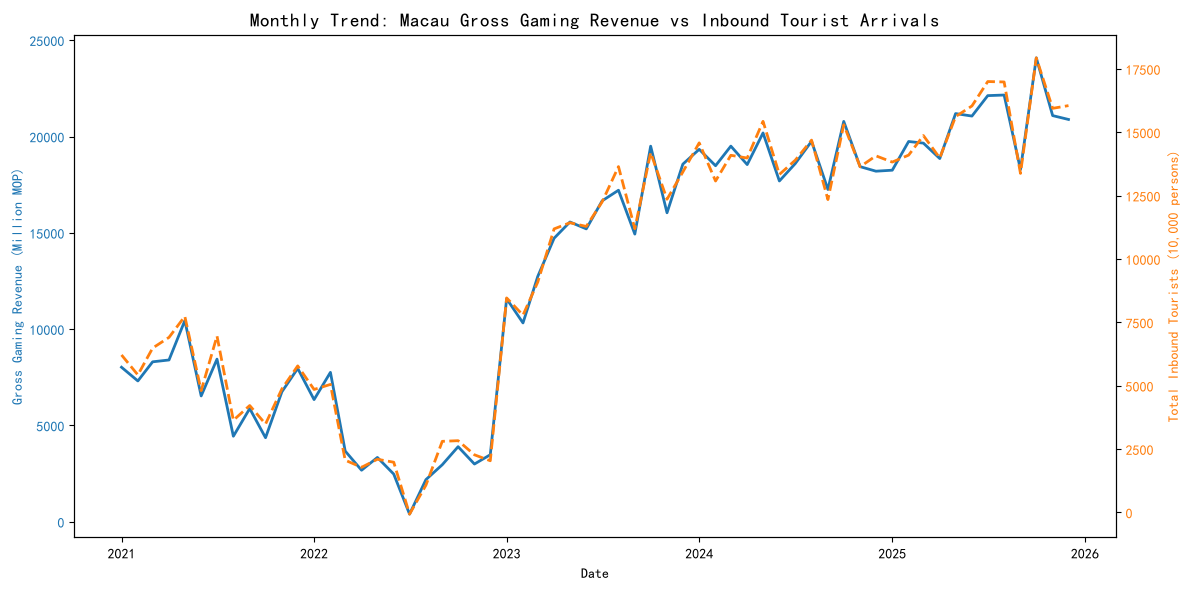

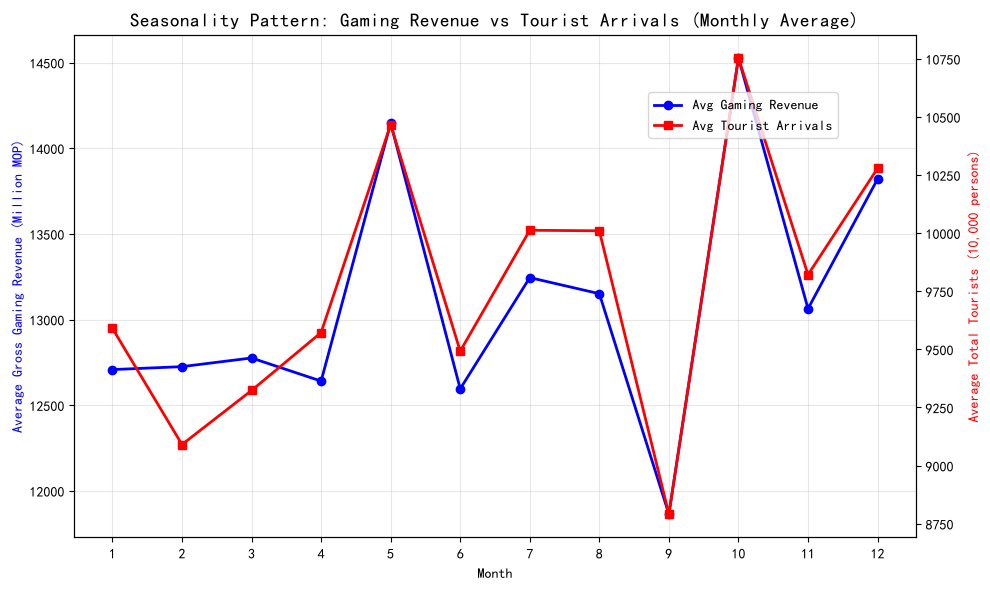

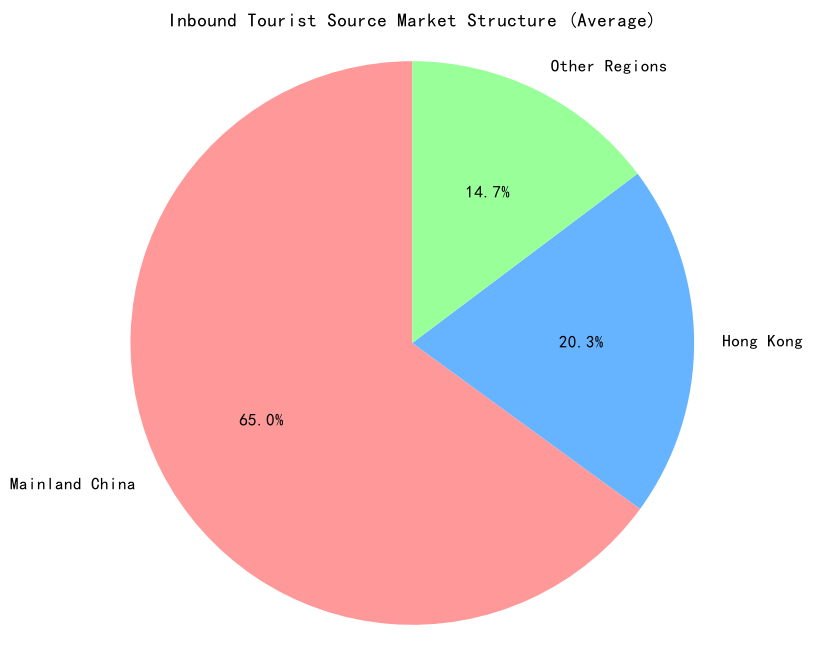

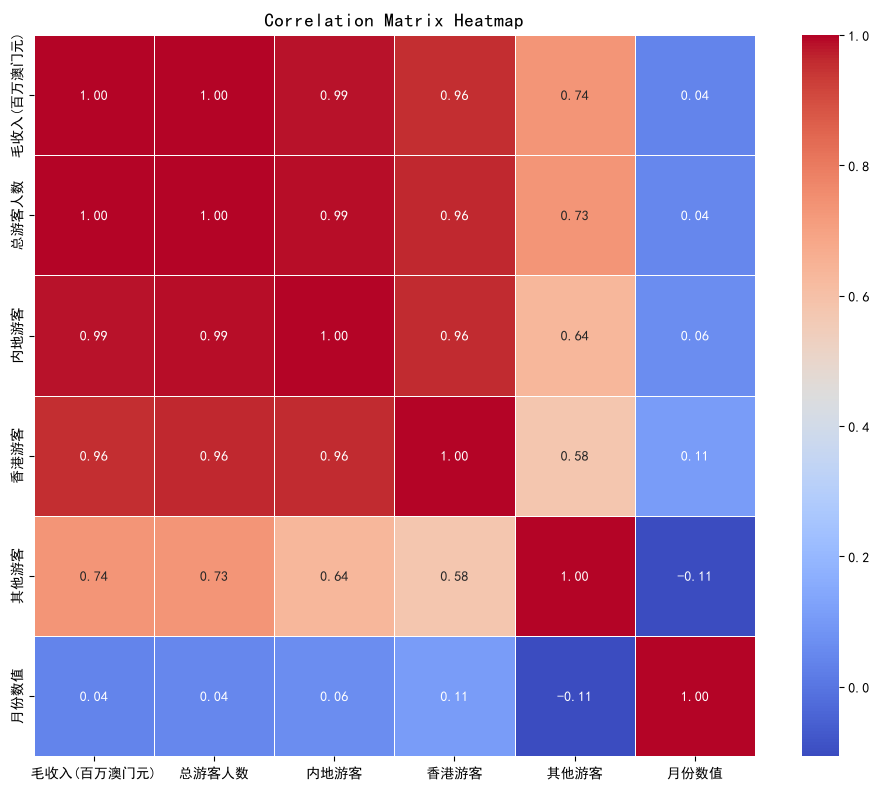

In [24]:
print("[EDA] Generating visualization plots...")

# ---------- Part A: 2 plots ----------
# 1. Dual-axis line chart: Gaming revenue vs tourist arrivals trend
fig, ax1 = plt.subplots(figsize=(12, 6))
color1 = '#1f77b4'
ax1.set_xlabel('Date')
ax1.set_ylabel('Gross Gaming Revenue (Million MOP)', color=color1)
ax1.plot(df['日期'], df['毛收入(百万澳门元)'], color=color1, linewidth=2, label='Gross Gaming Revenue')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = '#ff7f0e'
ax2.set_ylabel('Total Inbound Tourists (10,000 persons)', color=color2)
ax2.plot(df['日期'], df['总游客人数'], color=color2, linewidth=2, linestyle='--', label='Total Tourists')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Monthly Trend: Macau Gross Gaming Revenue vs Inbound Tourist Arrivals', fontsize=14)
fig.tight_layout()
plt.show()

# 2. Seasonal trend chart: Multi-year average by month
monthly_avg = df.groupby('月份数值')[['毛收入(百万澳门元)', '总游客人数']].mean()

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(monthly_avg.index, monthly_avg['毛收入(百万澳门元)'], 'b-o', linewidth=2, markersize=6, label='Avg Gaming Revenue')
ax1.set_xlabel('Month')
ax1.set_ylabel('Average Gross Gaming Revenue (Million MOP)', color='b')
ax1.set_xticks(range(1, 13))
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(monthly_avg.index, monthly_avg['总游客人数'], 'r-s', linewidth=2, markersize=6, label='Avg Tourist Arrivals')
ax2.set_ylabel('Average Total Tourists (10,000 persons)', color='r')

plt.title('Seasonality Pattern: Gaming Revenue vs Tourist Arrivals (Monthly Average)', fontsize=14)
fig.legend(loc='upper right', bbox_to_anchor=(0.85, 0.85))
plt.tight_layout()
plt.show()

# ---------- Part B: 2 plots ----------
# 1. Pie chart: Tourist source market share (overall average)
avg_ratios = [df['内地游客占比'].mean(), df['香港游客占比'].mean(), df['其他游客占比'].mean()]
labels = ['Mainland China', 'Hong Kong', 'Other Regions']
colors = ['#ff9999', '#66b3ff', '#99ff99']

plt.figure(figsize=(8, 8))
plt.pie(avg_ratios, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
plt.title('Inbound Tourist Source Market Structure (Average)', fontsize=14)
plt.axis('equal')
plt.show()

# 2. Heatmap: Correlation matrix of all variables
corr_vars = ['毛收入(百万澳门元)', '总游客人数', '内地游客', '香港游客', '其他游客', '月份数值']
corr_matrix = df[corr_vars].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, linewidths=0.5)
plt.title('Correlation Matrix Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

## MODULE 4: Model Development

In [25]:
print("[Model Development] Training three regression models...")

# Train/test split: 80% training, 20% test (no shuffle for time-series data)
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
y_train = train_df['毛收入(百万澳门元)']
y_test = test_df['毛收入(百万澳门元)']

# ---------- Model 1: Simple Linear Regression (Total tourists → Gaming revenue) ----------
model1 = LinearRegression()
X_train1 = train_df[['总游客人数']]
X_test1 = test_df[['总游客人数']]
model1.fit(X_train1, y_train)

y_pred_train1 = model1.predict(X_train1)
y_pred_test1 = model1.predict(X_test1)

print(f"\nModel 1 (Simple Linear Regression):")
print(f"  Coefficient: Each 10,000 increase in total tourists raises revenue by {model1.coef_[0]:.2f} million MOP")
print(f"  Intercept: {model1.intercept_:.2f}")

# ---------- Model 2: Multiple Linear Regression (Source markets → Gaming revenue) ----------
model2 = LinearRegression()
X_train2 = train_df[['内地游客', '香港游客', '其他游客']]
X_test2 = test_df[['内地游客', '香港游客', '其他游客']]
model2.fit(X_train2, y_train)

y_pred_train2 = model2.predict(X_train2)
y_pred_test2 = model2.predict(X_test2)

print(f"\nModel 2 (Multiple Linear Regression):")
print(f"  Mainland China coefficient: {model2.coef_[0]:.2f}")
print(f"  Hong Kong coefficient: {model2.coef_[1]:.2f}")
print(f"  Other regions coefficient: {model2.coef_[2]:.2f}")
max_idx = np.argmax(model2.coef_)
print(f"  Most influential source market: {['Mainland China', 'Hong Kong', 'Other Regions'][max_idx]}")

# ---------- Model 3: Lagged Variable Regression (Current + previous month tourists) ----------
# Create lagged tourist variable (previous month value)
df['上月总游客人数'] = df['总游客人数'].shift(1)
df_lag = df.dropna().reset_index(drop=True)  # Drop first row with missing lag value

# Re-split train/test set for lagged model
train_lag, test_lag = train_test_split(df_lag, test_size=0.2, shuffle=False)
y_train_lag = train_lag['毛收入(百万澳门元)']
y_test_lag = test_lag['毛收入(百万澳门元)']

model3 = LinearRegression()
X_train3 = train_lag[['总游客人数', '上月总游客人数']]
X_test3 = test_lag[['总游客人数', '上月总游客人数']]
model3.fit(X_train3, y_train_lag)

y_pred_train3 = model3.predict(X_train3)
y_pred_test3 = model3.predict(X_test3)

print(f"\nModel 3 (Lagged Variable Regression):")
print(f"  Current month tourist coefficient: {model3.coef_[0]:.2f}")
print(f"  Previous month tourist coefficient: {model3.coef_[1]:.2f}")

[Model Development] Training three regression models...

Model 1 (Simple Linear Regression):
  Coefficient: Each 10,000 increase in total tourists raises revenue by 1.33 million MOP
  Intercept: 167.34

Model 2 (Multiple Linear Regression):
  Mainland China coefficient: 1.39
  Hong Kong coefficient: 1.17
  Other regions coefficient: 1.29
  Most influential source market: Mainland China

Model 3 (Lagged Variable Regression):
  Current month tourist coefficient: 1.30
  Previous month tourist coefficient: 0.02


## MODULE 5: Model Evaluation

[Model Evaluation] Performance metrics for each model:

Model 1 (Simple Linear Regression):
  Training set R² = 0.9943
  Test set R² = 0.9299
  Test set MSE = 194406.46
  Test set RMSE = 440.92

Model 2 (Multiple Linear Regression):
  Training set R² = 0.9943
  Test set R² = 0.9274
  Test set MSE = 201384.90
  Test set RMSE = 448.76

Model 3 (Lagged Variable Regression):
  Training set R² = 0.9950
  Test set R² = 0.9343
  Test set MSE = 170167.43
  Test set RMSE = 412.51

=== Final Conclusion ===
Model 3 achieves the highest test set R² (0.9343). Adding lagged variable improves prediction accuracy for gaming revenue.

[Model Diagnostics] Generating diagnostic plots for Model 3...


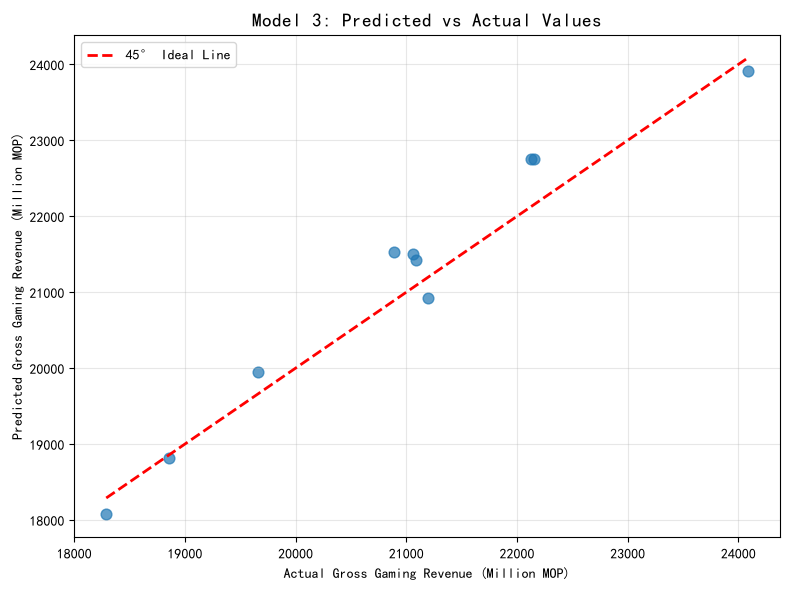

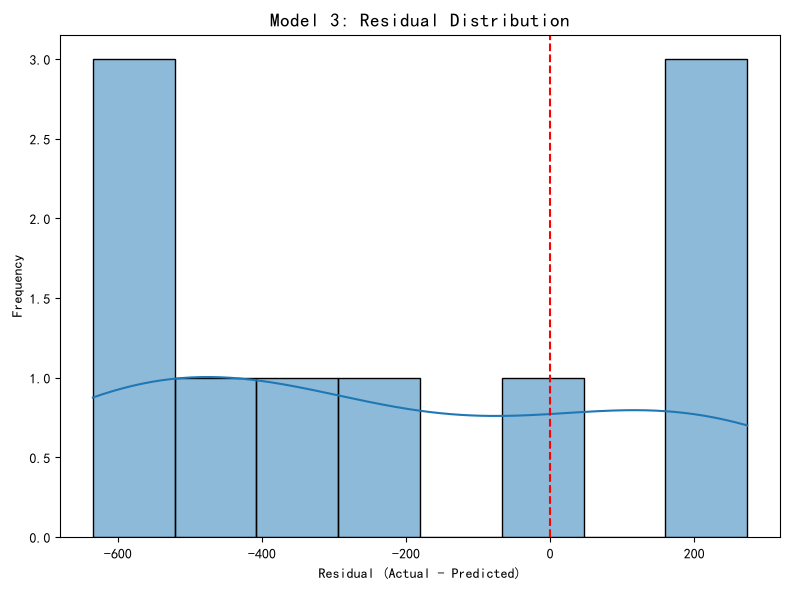

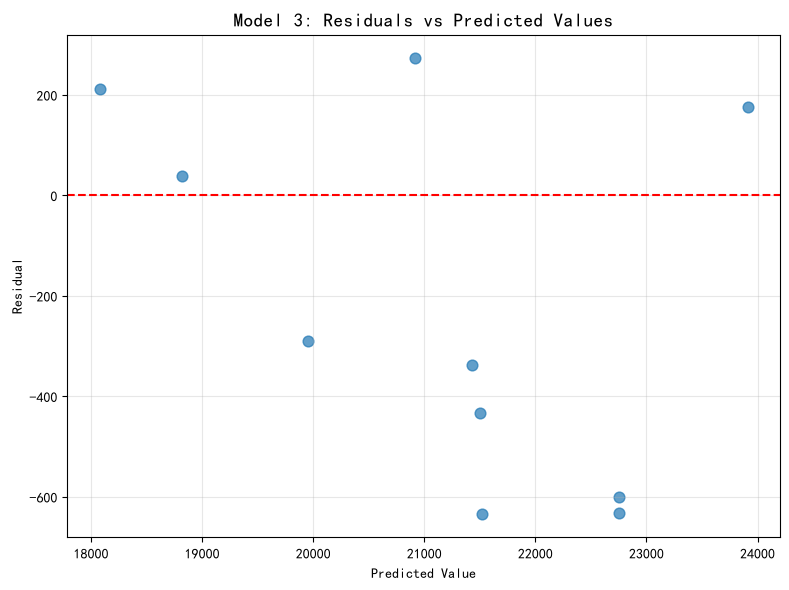

In [26]:
print("[Model Evaluation] Performance metrics for each model:")

# Define evaluation metric calculation function
def calc_metrics(y_true_train, y_pred_train, y_true_test, y_pred_test, model_name):
    r2_train = r2_score(y_true_train, y_pred_train)
    r2_test = r2_score(y_true_test, y_pred_test)
    mse_test = mean_squared_error(y_true_test, y_pred_test)
    rmse_test = np.sqrt(mse_test)
    
    print(f"\n{model_name}:")
    print(f"  Training set R² = {r2_train:.4f}")
    print(f"  Test set R² = {r2_test:.4f}")
    print(f"  Test set MSE = {mse_test:.2f}")
    print(f"  Test set RMSE = {rmse_test:.2f}")
    return r2_test

# Compute test set R² for all three models
r2_1 = calc_metrics(y_train, y_pred_train1, y_test, y_pred_test1, "Model 1 (Simple Linear Regression)")
r2_2 = calc_metrics(y_train, y_pred_train2, y_test, y_pred_test2, "Model 2 (Multiple Linear Regression)")
r2_3 = calc_metrics(y_train_lag, y_pred_train3, y_test_lag, y_pred_test3, "Model 3 (Lagged Variable Regression)")

# Final conclusion summary
best_r2 = max(r2_1, r2_2, r2_3)
best_model = [r2_1, r2_2, r2_3].index(best_r2) + 1
print(f"\n=== Final Conclusion ===")
print(f"Model {best_model} achieves the highest test set R² ({best_r2:.4f}).", end="")
print(" Adding lagged variable improves prediction accuracy for gaming revenue." if best_model == 3 else " It delivers the best prediction performance.")

# ---------- Model Diagnostic Plots (using Model 3 as example) ----------
print("\n[Model Diagnostics] Generating diagnostic plots for Model 3...")
residuals = y_test_lag - y_pred_test3

# 1. Predicted vs Actual values scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test_lag, y_pred_test3, alpha=0.7, s=60)
plt.plot([y_test_lag.min(), y_test_lag.max()], 
         [y_test_lag.min(), y_test_lag.max()], 
         'r--', linewidth=2, label='45° Ideal Line')
plt.xlabel('Actual Gross Gaming Revenue (Million MOP)')
plt.ylabel('Predicted Gross Gaming Revenue (Million MOP)')
plt.title('Model 3: Predicted vs Actual Values', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Residual distribution histogram
plt.figure(figsize=(8, 6))
sns.histplot(residuals, kde=True, bins=8)
plt.xlabel('Residual (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Model 3: Residual Distribution', fontsize=14)
plt.axvline(x=0, color='r', linestyle='--')
plt.tight_layout()
plt.show()

# 3. Residuals vs Predicted values scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_pred_test3, residuals, alpha=0.7, s=60)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Value')
plt.ylabel('Residual')
plt.title('Model 3: Residuals vs Predicted Values', fontsize=14)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()